In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Dataset path
csv_path = "Data/loan.csv"

# Required features
features = [
    "loan_amnt",
    "term",
    "int_rate",
    "installment",
    "grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "addr_state",
    "dti",
    "delinq_2yrs",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc"
]

# Load required columns only
required_columns = features + ["loan_status"]

df = pd.read_csv(
    csv_path,
    usecols=required_columns,
    low_memory=False
)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (2260668, 19)


,loan_amnt,term,int_rate,installment,grade,emp_length,home_ownership,annual_inc,verification_status,loan_status,purpose,addr_state,dti,delinq_2yrs,open_acc,pub_rec,revol_bal,revol_util,total_acc
0,2500,36 months,13.56,84.92,C,10+ years,RENT,55000.0,Not Verified,Current,debt_consolidation,NY,18.24,0.0,9.0,1.0,4341,10.3,34.0
1,30000,60 months,18.94,777.23,D,10+ years,MORTGAGE,90000.0,Source Verified,Current,debt_consolidation,LA,26.52,0.0,13.0,1.0,12315,24.2,44.0
2,5000,36 months,17.97,180.69,D,6 years,MORTGAGE,59280.0,Source Verified,Current,debt_consolidation,MI,10.51,0.0,8.0,0.0,4599,19.1,13.0
3,4000,36 months,18.94,146.51,D,10+ years,MORTGAGE,92000.0,Source Verified,Current,debt_consolidation,WA,16.74,0.0,10.0,0.0,5468,78.1,13.0
4,30000,60 months,16.14,731.78,C,10+ years,MORTGAGE,57250.0,Not Verified,Current,debt_consolidation,MD,26.35,0.0,12.0,0.0,829,3.6,26.0


In [4]:
# Keep only Fully Paid and Charged Off loans
df = df[
    df["loan_status"].isin(["Fully Paid", "Charged Off"])
].copy()

# Sample 15% of the filtered dataset for faster execution
df = df.sample(
    frac=0.15,
    random_state=42
)

# Convert loan status into binary target
df["target"] = df["loan_status"].map({
    "Fully Paid": 0,
    "Charged Off": 1
})

# Separate input features and target
X = df[features]
y = df["target"]

print("Dataset Shape:", df.shape)

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

print("\nTarget Percentage:")
print(y.value_counts(normalize=True) * 100)

Dataset Shape: (195541, 20)

Features Shape: (195541, 18)
Target Shape: (195541,)

Target Distribution:
target
0    156014
1     39527
Name: count, dtype: int64

Target Percentage:
target
0    79.785825
1    20.214175
Name: proportion, dtype: float64


In [5]:
# First split: 60% training and 40% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Second split: 20% validation and 20% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Testing Set:", X_test.shape)

print("\nTraining Percentage:", len(X_train) / len(X) * 100)
print("Validation Percentage:", len(X_val) / len(X) * 100)
print("Testing Percentage:", len(X_test) / len(X) * 100)

Training Set: (117324, 18)
Validation Set: (39108, 18)
Testing Set: (39109, 18)

Training Percentage: 59.99969315897945
Validation Percentage: 19.999897719659813
Testing Percentage: 20.000409121360736


In [6]:
# Identify numerical columns
num_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical columns
cat_cols = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Columns:")
print(num_cols)

print("\nCategorical Columns:")
print(cat_cols)

Numerical Columns:
['loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'delinq_2yrs', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc']

Categorical Columns:
['term', 'grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'addr_state']


In [7]:
# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, num_cols),
        ("cat", categorical_pipeline, cat_cols)
    ]
)

# Fit on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation data
X_val_processed = preprocessor.transform(X_val)

print("Training Data Shape:", X_train_processed.shape)
print("Validation Data Shape:", X_val_processed.shape)

Training Data Shape: (117324, 104)
Validation Data Shape: (39108, 104)


In [8]:
# Different maximum depths
depths = [1, 3, 5, 10, None]

train_accuracies = []
val_accuracies = []

for depth in depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    # Train model
    model.fit(X_train_processed, y_train)

    # Predictions
    train_pred = model.predict(X_train_processed)
    val_pred = model.predict(X_val_processed)

    # Calculate accuracy
    train_acc = accuracy_score(y_train, train_pred)
    val_acc = accuracy_score(y_val, val_pred)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Depth {depth}: "
        f"Train Accuracy = {train_acc:.4f}, "
        f"Validation Accuracy = {val_acc:.4f}"
    )

Depth 1: Train Accuracy = 0.7979, Validation Accuracy = 0.7979
Depth 3: Train Accuracy = 0.7979, Validation Accuracy = 0.7979
Depth 5: Train Accuracy = 0.7992, Validation Accuracy = 0.7977
Depth 10: Train Accuracy = 0.8106, Validation Accuracy = 0.7923
Depth None: Train Accuracy = 1.0000, Validation Accuracy = 0.7030


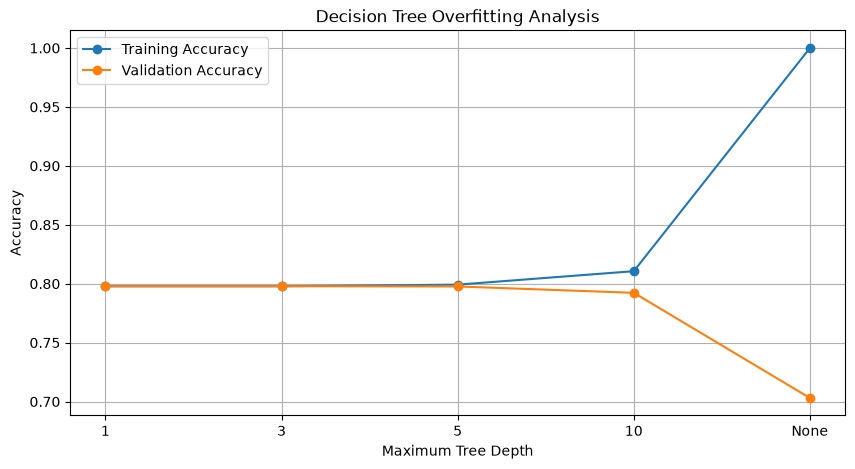

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(
    ["1", "3", "5", "10", "None"],
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    ["1", "3", "5", "10", "None"],
    val_accuracies,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")

plt.title("Decision Tree Overfitting Analysis")

plt.legend()
plt.grid(True)

plt.show()

In [10]:
# Create Logistic Regression model
log_model = LogisticRegression(
    max_iter=1000
)

# Create complete preprocessing and model pipeline
cv_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", log_model)
])

# Perform 5-fold cross validation
cv_scores = cross_val_score(
    cv_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

# Display results
print("Cross Validation Scores:", cv_scores)

print(
    "\nMean Accuracy: {:.4f} +/- {:.4f}".format(
        cv_scores.mean(),
        cv_scores.std()
    )
)

print("Standard Deviation:", cv_scores.std())

Cross Validation Scores: [0.79825272 0.79919028 0.80055402 0.7984658  0.80041766]

Mean Accuracy: 0.7994 +/- 0.0010
Standard Deviation: 0.0009589056822802527


In [11]:
# Select one numerical feature
X_demo = X[["loan_amnt"]]

# Use the same train, validation and test split
X_demo_train = X_train[["loan_amnt"]]
X_demo_val = X_val[["loan_amnt"]]
X_demo_test = X_test[["loan_amnt"]]

# WRONG WAY: Fit scaler on complete dataset
wrong_scaler = StandardScaler()

X_scaled_wrong = wrong_scaler.fit_transform(X_demo)

# CORRECT WAY: Fit scaler only on training data
correct_scaler = StandardScaler()

X_correct_train = correct_scaler.fit_transform(
    X_demo_train
)

# Transform validation and test data
X_correct_val = correct_scaler.transform(
    X_demo_val
)

X_correct_test = correct_scaler.transform(
    X_demo_test
)

# Compare results
print(
    "Wrong Scaling - Mean:",
    wrong_scaler.mean_[0]
)

print(
    "Correct Scaling - Mean:",
    correct_scaler.mean_[0]
)

print(
    "\nWrong Scaling - Standard Deviation:",
    wrong_scaler.scale_[0]
)

print(
    "Correct Scaling - Standard Deviation:",
    correct_scaler.scale_[0]
)

Wrong Scaling - Mean: 14415.301394592438
Correct Scaling - Mean: 14394.786872251201

Wrong Scaling - Standard Deviation: 8689.98315392093
Correct Scaling - Standard Deviation: 8688.089328855109


### Explanation

1. Wrong way: Scaling the entire dataset before splitting uses information from validation and test data.
2. This causes data leakage and may lead to misleading model evaluation.
3. Correct way: Split the data first and fit the scaler only on training data.
4. Use the same fitted scaler to transform validation and test data without fitting again.


# Classification of ML Problems

### 1. Spam Detection
- ML Type: Supervised Learning
- Reason: Emails are labelled as Spam or Not Spam.

### 2. Customer Segmentation
- ML Type: Unsupervised Learning
- Reason: Customers are grouped based on similar behaviour without predefined labels.

### 3. House Price Prediction
- ML Type: Supervised Learning
- Reason: The model learns from previous house prices to predict new prices.

### 4. Anomaly Detection
- ML Type: Unsupervised Learning
- Reason: Identifies unusual patterns without predefined labels.



# Machine Learning Workflow – 7 Steps

1. **Problem Definition:** Understand the problem and define the goal.

2. **Data Collection:** Collect relevant data from different sources.

3. **Data Preprocessing:** Handle missing values, duplicates, and incorrect data.

4. **Exploratory Data Analysis (EDA):** Analyze data using statistics and visualizations.

5. **Feature Engineering:** Select and transform useful features.

6. **Model Training and Evaluation:** Train the ML model and evaluate its performance using suitable metrics.

7. **Deployment and Monitoring:** Deploy the model and monitor its performance regularly.